# 00 · Setup and example data

This is the first notebook of a short series on detecting marine heatwaves (MHWs)
with **xrMHW**. It checks your installation, downloads the example data and shows
what xrMHW needs from a dataset before you run it on your own data.

| Notebook | What it covers |
|---|---|
| **00 · Setup and example data** | Installation, example data, input requirements |
| 01 · A single time series | Detection at one point, the outputs, validation against the reference code |
| 02 · Sea surface maps | Detection on a latitude–longitude grid, maps, marine cold spells |
| 03 · Subsurface marine heatwaves | Detection over depth, latitude and longitude; sections, profiles and a 3-D view |
| 04 · Many files, Dask and Zarr | `open_mfdataset`, chunk planning, a local Dask cluster, writing to Zarr |
| 05 · Troubleshooting | Common errors, what causes them and how to fix them |

## 1. What xrMHW does, and what it does not

xrMHW applies the marine heatwave definition of Hobday et al. (2016) to every grid
cell of an `xarray` dataset. A marine heatwave is a period of at least five days in
which temperature stays above the seasonally varying 90th percentile of a baseline
period. Each grid cell is treated as an independent daily time series, so the same
code runs on a single mooring, a sea surface temperature map or a four-dimensional
ocean reanalysis. Dask spreads the work over the grid cells and keeps the memory
bounded.

The detection is **pointwise**. xrMHW tells you, for every cell and every day,
whether that cell is in a marine heatwave and how intense it is. It does not join
neighbouring cells into objects, so it does not give the area, volume or
trajectory of an event. Tools such as Ocetrac do that tracking; xrMHW can feed
them.

With its default settings, xrMHW reproduces the reference implementation,
`marineHeatWaves` (Eric Oliver), to floating-point precision. Notebook 01 checks that.

## 2. Installation

Run one of these in a terminal (Miniforge Prompt/Conda/Python Terminal on Windows), not in the notebook.

**With conda (recommended, cartopy installs more easily from conda-forge):**

```bash
git clone https://github.com/Gabo2000s/xarray_MHW-xrMHW-.git
cd xarray_MHW-xrMHW-
conda env create -f examples/environment.yml
conda activate xrmhw-examples
pip install -e .
```

**With pip:**

```bash
git clone https://github.com/Gabo2000s/xarray_MHW-xrMHW-.git
cd xarray_MHW-xrMHW-
pip install ".[examples]"
```

The `examples` extra adds what the notebooks use besides xrMHW itself: pooch,
matplotlib, cartopy, cmocean, plotly, zarr and Dask's distributed scheduler.

## 3. Check the installation

Import xrMHW **only** as an installed package. Older examples added the repository
folder to `sys.path`. That imports whichever copy of `xrMHW.py` sits in that folder,
which may not be the version you installed. The cell below prints where the module
comes from.

In [1]:
import sys
from pathlib import Path

import dask
import numpy as np
import pandas as pd
import xarray as xr

import xrMHW

print(f"xrMHW  {xrMHW.__version__}  from {Path(xrMHW.__file__).resolve()}")
print(f"xarray {xr.__version__}, dask {dask.__version__}, numpy {np.__version__}, "
      f"Python {sys.version.split()[0]}")

xrMHW  3.0.0  from D:\Proyectos\xarray_MHW-xrMHW-\xrMHW.py
xarray 2026.7.0, dask 2026.8.0, numpy 1.26.4, Python 3.11.16


The path should point to your environment's `site-packages` folder, or to the
cloned repository if you installed it in editable mode (`pip install -e .`). The
version should be 3.0.0 or later. These notebooks use the v3 interface.

## 4. Download the example data

The two example files are archived on Zenodo
([10.5281/zenodo.22909109](https://doi.org/10.5281/zenodo.22909109)):

| File                        | Content                                                                                                                                                                                                | Size  |
| -----------------------------| --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------| -------|
| `xrmhw_glorys_4d_subset.nc` | Daily potential temperature from the GLORYS12V1 reanalysis, 1993-01-01 to 2025-11-25, 33 levels from 0.5 to 644 m, 12 × 12 cells at 1/12° on the south-eastern slope of the Grand Bank of Newfoundland | 79 MB |
| `xrmhw_ostia_sst_3d.nc`     | Daily sea surface temperature from the OSTIA reprocessed analysis, 1990-01-01 to 2023-01-01, 41 × 45 cells at 0.05° off the Pacific coast of Baja California                                           | 7 MB  |

[pooch](https://www.fatiando.org/pooch) downloads each file the first time you ask
for it, checks its checksum and keeps it in a cache folder. Later calls, and the
other notebooks, read the cached copy without downloading again, so they also
work offline.

The data are E.U. Copernicus Marine Service Information
([10.48670/moi-00021](https://doi.org/10.48670/moi-00021),
[10.48670/moi-00168](https://doi.org/10.48670/moi-00168)) and are redistributed
under the Copernicus Marine Service licence.

In [2]:
import pooch

EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("xrmhw"),
    base_url="doi:10.5281/zenodo.22909109/",
    registry={
        "xrmhw_glorys_4d_subset.nc": "md5:5555737e45f1c6cde9f657e50f456693",
        "xrmhw_ostia_sst_3d.nc": "md5:74a2da227394e4463f203f6b388518ee",
    },
)
glorys_path = EXAMPLE_DATA.fetch("xrmhw_glorys_4d_subset.nc")
ostia_path = EXAMPLE_DATA.fetch("xrmhw_ostia_sst_3d.nc")
print("cache folder:", EXAMPLE_DATA.abspath)

cache folder: C:\Users\gabo2\AppData\Local\xrmhw\xrmhw\Cache


## 5. A first look at the data

### GLORYS12V1: four dimensions

Open the file without loading it into memory. `xr.open_dataset` only reads the
metadata; values are read when a computation needs them.

In [3]:
glorys = xr.open_dataset(glorys_path)
glorys

<xarray.Dataset> Size: 457MB
Dimensions:    (time: 12017, depth: 33, latitude: 12, longitude: 12)
Coordinates:
  * time       (time) datetime64[ns] 96kB 1993-01-01 1993-01-02 ... 2025-11-25
  * depth      (depth) float32 132B 0.494 1.541 2.646 ... 453.9 541.1 643.6
  * latitude   (latitude) float32 48B 43.5 43.58 43.67 ... 44.25 44.33 44.42
  * longitude  (longitude) float32 48B -49.5 -49.42 -49.33 ... -48.67 -48.58
Data variables:
    thetao     (time, depth, latitude, longitude) float64 457MB ...
Attributes:
    title:       xrMHW example data: GLORYS12V1 4-D subset (Grand Banks slope)
    source:      E.U. Copernicus Marine Service Information (CMEMS), Global O...
    doi:         10.48670/moi-00021
    references:  Lellouche et al. (2021); https://github.com/Gabo2000s/xarray...
    subset:      12x12 cells, all levels, full record
    history:     2026-09-23 subset by make_example_data.py from GLORYS_GrandB...

Two things in this output are worth knowing before you run a detection.

**Packing.** On disk, `thetao` is stored as 16-bit integers with a `scale_factor`
and an `add_offset`, as Copernicus serves it. xarray unpacks it when reading, so the
values you see are in °C. The unpacked array is four times larger than the file
suggests: the memory you need depends on the decoded size, not on the file size.

In [4]:
enc = glorys["thetao"].encoding
print(f"on disk: {enc['dtype']}, scale_factor={enc['scale_factor']:.3g}, "
      f"add_offset={enc['add_offset']}")
print(f"decoded in memory: {glorys['thetao'].dtype}, "
      f"{glorys['thetao'].nbytes / 2**20:.0f} MiB "
      f"({glorys['thetao'].astype('float32').nbytes / 2**20:.0f} MiB as float32)")

on disk: int16, scale_factor=0.000732, add_offset=21.0
decoded in memory: float64, 436 MiB (218 MiB as float32)


**Cells below the sea floor are missing values.** The window crosses the edge of the
Grand Bank: on the shelf the water column ends at a few tens of metres, offshore it
reaches the deepest level. xrMHW skips cells that are missing for the whole record,
so you do not need to mask them yourself.

In [5]:
first_day = glorys["thetao"].isel(time=0)
n_levels = first_day.notnull().sum("depth")
bottom_depth = glorys["depth"].isel(depth=(n_levels - 1).clip(min=0)).where(n_levels > 0)
print(f"column bottoms from {float(bottom_depth.min()):.0f} m to "
      f"{float(bottom_depth.max()):.0f} m; "
      f"{int((n_levels == glorys.sizes['depth']).sum())} of {n_levels.size} columns "
      "reach the deepest level")

column bottoms from 34 m to 644 m; 69 of 144 columns reach the deepest level


### OSTIA: three dimensions

In [6]:
ostia = xr.open_dataset(ostia_path)
sst = ostia["analysed_sst"]
print(sst.dims, sst.shape)
print(f"units attribute: {sst.attrs.get('units')}; values from {float(sst.min()):.1f} "
      f"to {float(sst.max()):.1f}")
print(f"cells missing for the whole record: {float(sst.isnull().all('time').mean()):.0%}")

('time', 'latitude', 'longitude') (12054, 41, 45)
units attribute: kelvin; values from 11.8 to 30.2
cells missing for the whole record: 87%


Look at those two lines together. The `units` attribute says **kelvin**, but sea
surface temperatures of 12 to 30 K are impossible: the values are already in °C
and the attribute is wrong, a leftover from an earlier processing step. Metadata
errors like this are common, so check the values, not only the attributes.
Notebook 02 fixes the attribute before the detection.

Most of the grid (87%) is missing for the whole record: land, and cells outside the
area kept in this example. xrMHW skips them.

### Where the two datasets are

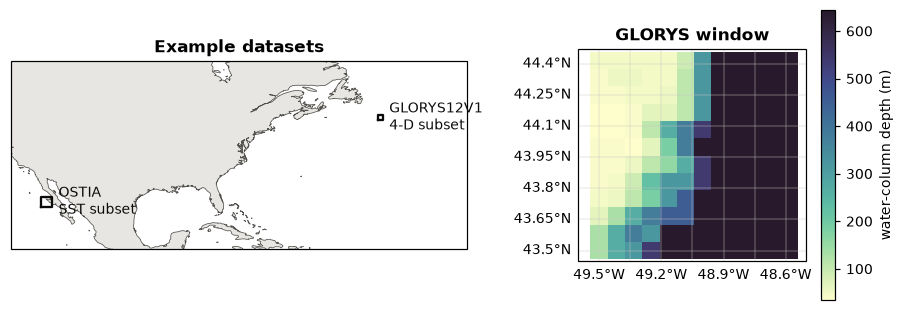

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9,
})
INK, INK2 = "#0b0b0b", "#52514e"


def box(ax, lat, lon, label, **kw):
    """Outline the extent of a dataset on a cartopy map and label it."""
    x0, x1, y0, y1 = float(lon.min()), float(lon.max()), float(lat.min()), float(lat.max())
    ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color=INK, lw=1.5,
            transform=ccrs.PlateCarree())
    ax.text(x1 + 1.2, y0 + 0.5 * (y1 - y0), label, va="center", color=INK,
            transform=ccrs.PlateCarree(), **kw)


fig = plt.figure(figsize=(10, 3.8))
grid = fig.add_gridspec(1, 2, width_ratios=[1.6, 1], wspace=0.3)
ax1 = fig.add_subplot(grid[0], projection=ccrs.PlateCarree())
ax1.set_extent([-122, -32, 18, 55], crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.LAND, facecolor="#e7e6e2")
ax1.coastlines("50m", lw=0.5, color=INK2)
box(ax1, glorys.latitude, glorys.longitude, "GLORYS12V1\n4-D subset") ## shows the "box" of glorys (Grand Banks)
box(ax1, ostia.latitude, ostia.longitude, "OSTIA\nSST subset") ## shows the "box" of ostia (Baja California)
ax1.set_title("Example datasets")

ax2 = fig.add_subplot(grid[1], projection=ccrs.PlateCarree())
mesh = ax2.pcolormesh(glorys.longitude, glorys.latitude, bottom_depth,
                      cmap=cmocean.cm.deep, transform=ccrs.PlateCarree()) ## extract and show the maximum depth available in de Glorys data per pixel
ax2.set_extent([-49.6, -48.5, 43.45, 44.47])
gl = ax2.gridlines(draw_labels=True, lw=0.3, color="#c9c8c3")
gl.top_labels = gl.right_labels = False
fig.colorbar(mesh, ax=ax2, shrink=0.9, label="water-column depth (m)")
ax2.set_title("GLORYS window")
plt.show()

The right panel is the bathymetry *as the model sees it*: the depth of the deepest
level with data in each column. The shelf (west) has columns of 30–60 m, and the
slope (east) has columns that reach the deepest level, 644 m. Notebook 03 uses this
contrast.

## 6. What xrMHW needs from your data

xrMHW asks for very little, but the few requirements matter:

1. **A `time` coordinate** with datetimes. The other dimensions can have any name
   (`lat`, `nav_lat`, `depth`, `lev`...) and there can be any number of them.
2. **Daily, contiguous data.** One value per day, with no missing dates. Missing
   *values* (NaN) are fine: runs of up to `max_gap_interp` days (default 2) are
   filled by linear interpolation, and longer gaps stay missing. Missing *dates*
   are not fine, because xrMHW counts durations in time steps.
3. **The standard calendar.** Model output on `noleap` or `360_day` calendars must
   be converted first (see notebook 05).
4. **Time in a single Dask chunk.** Each cell needs its whole record to compute its
    climatology; time should be -1 to get all the time series of each pixel/voxel ("time": -1). Chunk over the other dimensions instead, e.g.
   `ds.chunk({"time": -1, "latitude": 20, "longitude": 20})`.The chunks works like substets of the data, which allow to run the MHWs detection in laptops with lower working memory (RAM memory) than the size of the data. 
5. **A baseline period inside the record.** `clim_period=(1993, 2022)` must fall
   within the years of the data. Hobday et al. (2016) recommend at least 30 years.
6. **Temperature in °C** (recommended). Detection works in any unit, but the output
   attributes say °C. Check the values as well as the `units` attribute.

The function below checks these points. It is a convenience for these notebooks,
not part of xrMHW; copy it if it helps.

In [9]:
def check_input(ds, var, clim_period):
    """Print a checklist of xrMHW's input requirements for ds[var]."""
    ok = True

    def report(passed, message):
        nonlocal ok
        ok &= passed
        print(("  ok    " if passed else "  FIX   ") + message)

    print(f"Checking '{var}' for clim_period={clim_period}")
    has_time = "time" in ds.indexes
    report(has_time, "'time' is a coordinate" if has_time
           else f"no 'time' coordinate; dimensions are {list(ds.dims)}")
    if not has_time:
        return False

    time = ds.indexes["time"]
    calendar = getattr(ds["time"].dt, "calendar", "standard")
    report(calendar in ("standard", "gregorian", "proleptic_gregorian"),
           f"calendar is '{calendar}'")
    steps = np.unique(np.diff(time.values).astype("timedelta64[h]").astype(int))
    report(steps.tolist() == [24], "daily with no missing dates" if steps.tolist() == [24]
           else f"time steps (hours) are {steps[:5].tolist()}: not contiguous daily")
    years = time.year
    inside = years.min() <= clim_period[0] and clim_period[1] <= years.max()
    report(inside, f"baseline {clim_period[0]}-{clim_period[1]} within the record "
                   f"{years.min()}-{years.max()}")
    report(clim_period[1] - clim_period[0] + 1 >= 30,
           f"baseline is {clim_period[1] - clim_period[0] + 1} years (30 recommended)")
    chunks = ds[var].chunksizes.get("time")
    report(chunks is None or len(chunks) == 1,
           "time is in one chunk" if chunks is None or len(chunks) == 1
           else f"time is split into {len(chunks)} chunks: use .chunk({{'time': -1}})")
    units = str(ds[var].attrs.get("units", "?"))
    report(units.lower() in ("degc", "degrees_c", "celsius", "°c", "degree_celsius"),
           f"units attribute is '{units}'")
    # A cheap look at the values, from the first and last days only
    sample = ds[var].isel(time=[0, -1])
    vmin, vmax = float(sample.min()), float(sample.max())
    looks_celsius = -3 < vmin and vmax < 40
    report(looks_celsius, f"values from {vmin:.1f} to {vmax:.1f} look like °C"
           if looks_celsius else f"values from {vmin:.1f} to {vmax:.1f} do not look like °C")
    return ok

## Run the function to verify the characteristics of the data. eg. "glorys" correspond to the dataset, "thetao" to the variable
check_input(glorys, "thetao", (1993, 2022))
print()
_ = check_input(ostia, "analysed_sst", (1991, 2020))

Checking 'thetao' for clim_period=(1993, 2022)
  ok    'time' is a coordinate
  ok    calendar is 'proleptic_gregorian'
  ok    daily with no missing dates
  ok    baseline 1993-2022 within the record 1993-2025
  ok    baseline is 30 years (30 recommended)
  ok    time is in one chunk
  ok    units attribute is 'degrees_C'
  ok    values from -0.1 to 14.0 look like °C

Checking 'analysed_sst' for clim_period=(1991, 2020)
  ok    'time' is a coordinate
  ok    calendar is 'proleptic_gregorian'
  ok    daily with no missing dates
  ok    baseline 1991-2020 within the record 1990-2023
  ok    baseline is 30 years (30 recommended)
  ok    time is in one chunk
  FIX   units attribute is 'kelvin'
  ok    values from 17.5 to 19.6 look like °C


GLORYS passes every check. OSTIA is flagged only for its `units` attribute, while
its values are fine: the attribute is what needs fixing (notebook 02).

## 7. Next

Continue with **01 · A single time series** to run your first detection and see
what each output variable means.

### References

- Hobday, A. J., et al. (2016). A hierarchical approach to defining marine heatwaves. *Progress in Oceanography*, 141, 227–238. https://doi.org/10.1016/j.pocean.2015.12.014
- Global Ocean Physics Reanalysis. E.U. Copernicus Marine Service Information (CMEMS). Marine Data Store (MDS). https://doi.org/10.48670/moi-00021
- Global Ocean OSTIA Sea Surface Temperature and Sea Ice Reprocessed. E.U. Copernicus Marine Service Information (CMEMS). Marine Data Store (MDS). https://doi.org/10.48670/moi-00168